# ECG Arrhythmia Classification – CART and Random Forest
UE24CS352A Machine Learning mini-project · Team: `<names / IDs – fill in>`

> **This project is an academic machine-learning experiment using a historical dataset. Its predictions are not medical diagnoses and must not be used for clinical decision-making. Clinical use would require rigorous independent validation, regulatory review, and appropriate medical oversight.**

**Goal:** predict the heart-condition class (UCI labels 1–16; class 1 = normal) of a patient from 279 ECG/patient features (UCI Arrhythmia dataset, 452 patients).
**Reference:** Zhou, Garcia & Rajbhandary, *Detecting Heart Abnormality using ECG with CART* (Stanford; R/rpart; ~80 % accuracy under its own protocol — **not our result**).

**Models used**
| Model | Why |
|---|---|
| CART – `DecisionTreeClassifier` (tuned + pruned) | the paper's method; interpretable rules |
| Random Forest – `RandomForestClassifier` (300 trees) | many trees voting; usually more accurate than one tree |

Preprocessing (not a predictive model): drop features that are >50 % missing in the training rows, then median-impute.

**How to run:** put `arrhythmia.data` in the same folder as this notebook, then *Kernel → Restart & Run All*.

## 1. Imports

In [1]:
import warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,
                             classification_report, f1_score)
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_score, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
warnings.filterwarnings("ignore")
SEED = 42

## 2. Load the data
The file has no header; `?` marks missing values; the **last column is the class label**.

In [2]:
path = next((p for p in (Path("arrhythmia.data"), Path("data/arrhythmia.data"), Path("../arrhythmia.data")) if p.is_file()), None)
assert path is not None, "arrhythmia.data not found - put it next to this notebook"
df = pd.read_csv(path, header=None, na_values="?")
assert df.shape == (452, 280), f"unexpected shape {df.shape}"
X, y = df.iloc[:, :-1], df.iloc[:, -1].astype(int)      # label is never part of X
X.columns = [f"f{i}" for i in range(1, 280)]
print("patients x features:", X.shape, "| classes present:", [int(c) for c in sorted(y.unique())])

patients x features: (452, 279) | classes present: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 14, 15, 16]


## 3. Understand the data
**Class balance:** class 1 (normal) dominates and several classes have only a handful of patients — so accuracy alone is misleading.

279
1     54.2
2      9.7
3      3.3
4      3.3
5      2.9
6      5.5
7      0.7
8      0.4
9      2.0
10    11.1
14     0.9
15     1.1
16     4.9

Always predicting class 1 would score 54.2% accuracy.


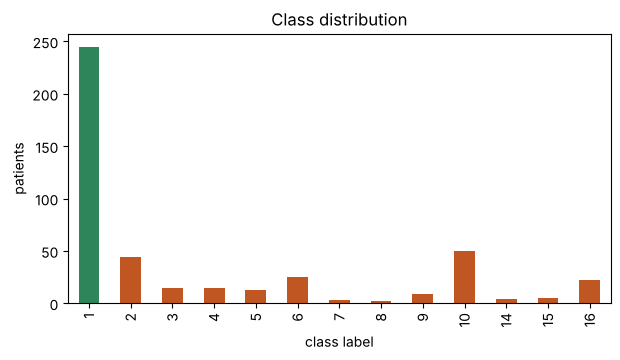

In [3]:
counts = y.value_counts().sort_index()
print((counts / len(y) * 100).round(1).to_string())
print(f"\nAlways predicting class 1 would score {(y == 1).mean():.1%} accuracy.")
counts.plot.bar(color=["#2f855a" if c == 1 else "#c05621" for c in counts.index], figsize=(7, 3.5))
plt.title("Class distribution"); plt.xlabel("class label"); plt.ylabel("patients"); plt.show()

**Missing values:** only a few features have gaps; feature 14 (the paper's "feature 14", the J-wave angle) is missing for most patients.

In [4]:
miss = X.isna().sum(); miss = miss[miss > 0].sort_values(ascending=False)
display(pd.DataFrame({"missing": miss, "percent": (miss / len(X) * 100).round(1)}))

,missing,percent
f14,376,83.2
f12,22,4.9
f11,8,1.8
f13,1,0.2
f15,1,0.2


## 4. Train / test split
The 30 % **test set is locked away** and used only once at the end. Stratified so each class appears in both parts.

In [5]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=SEED, stratify=y)
print(len(X_tr), "training patients,", len(X_te), "test patients")

316 training patients, 136 test patients


## 5. Preprocessing (learned from training rows only → no data leakage)
`DropMostlyMissing` drops features missing in more than 50 % of the **training** rows (this removes feature 14, as the paper did); then `SimpleImputer` fills remaining gaps with the **training median**. Both live inside the model pipeline, so during cross-validation they are re-learned on each training fold.

In [6]:
class DropMostlyMissing(BaseEstimator, TransformerMixin):
    def __init__(self, threshold=0.5):
        self.threshold = threshold
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.keep_ = X.columns[X.isna().mean() <= self.threshold]
        return self
    def transform(self, X):
        return pd.DataFrame(X)[self.keep_]

def make_pipeline(model):
    return Pipeline([("drop", DropMostlyMissing()), ("impute", SimpleImputer(strategy="median")), ("model", model)])

print("features dropped:", list(DropMostlyMissing().fit(X_tr).transform(X_tr.head(1)).columns.symmetric_difference(X_tr.columns)))

features dropped: ['f14']


## 6. Model 1 – CART decision tree, tuned and pruned
A tree asks yes/no questions about features; each split is the one that makes the groups purest (Gini / entropy). A fully grown tree **overfits**, so we tune its size and apply **cost-complexity pruning** (`ccp_alpha`: bigger = simpler tree). 5-fold cross-validation on the **training** rows chooses the settings.

In [7]:
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
grid = {"model__criterion": ["gini", "entropy"], "model__max_depth": [4, 6, 8, None],
        "model__min_samples_leaf": [1, 3, 5], "model__ccp_alpha": [0.0, 0.005, 0.01, 0.02]}
search = GridSearchCV(make_pipeline(DecisionTreeClassifier(random_state=SEED)), grid, cv=cv5, scoring="accuracy")
search.fit(X_tr, y_tr)
cart = search.best_estimator_
print("best settings:", {k.replace("model__", ""): v for k, v in search.best_params_.items()})
print(f"training CV accuracy: {search.best_score_:.3f}")

best settings: {'ccp_alpha': 0.02, 'criterion': 'gini', 'max_depth': 6, 'min_samples_leaf': 3}
training CV accuracy: 0.684


## 7. Model 2 – Random Forest
300 trees, each trained on a random sample of patients and features; they vote. Usually more accurate than a single tree, but harder to read.

In [8]:
rf = make_pipeline(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)).fit(X_tr, y_tr)
print("trained Random Forest with", rf.named_steps["model"].n_estimators, "trees")

trained Random Forest with 300 trees


## 8. Evaluation
* **Test set** (used once): accuracy, balanced accuracy, macro-F1.
* **10-fold cross-validation on all 452 patients** (repeated 3×): the same kind of CV the paper reports.

Macro-F1 averages quality over classes equally, so it exposes weak rare-class performance that accuracy hides.

In [9]:
cv10 = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=SEED)
rows = {}
for name, model in (("CART (pruned)", cart), ("Random Forest", rf)):
    pred = model.predict(X_te)
    cv_acc = cross_val_score(make_pipeline(model.named_steps["model"]), X, y, cv=cv10, scoring="accuracy").mean()
    rows[name] = {"Test accuracy": accuracy_score(y_te, pred), "Test balanced acc.": balanced_accuracy_score(y_te, pred),
                  "Test macro-F1": f1_score(y_te, pred, average="macro"), "10-fold CV accuracy (all rows)": cv_acc}
results = pd.DataFrame(rows).T.round(3)
results

,Test accuracy,Test balanced acc.,Test macro-F1,10-fold CV accuracy (all rows)
CART (pruned),0.632,0.261,0.237,0.669
Random Forest,0.728,0.360,0.369,0.739


## 9. Confusion matrix and per-class results (Random Forest, test set)
Rows = true class, columns = predicted class. The diagonal is correct predictions.

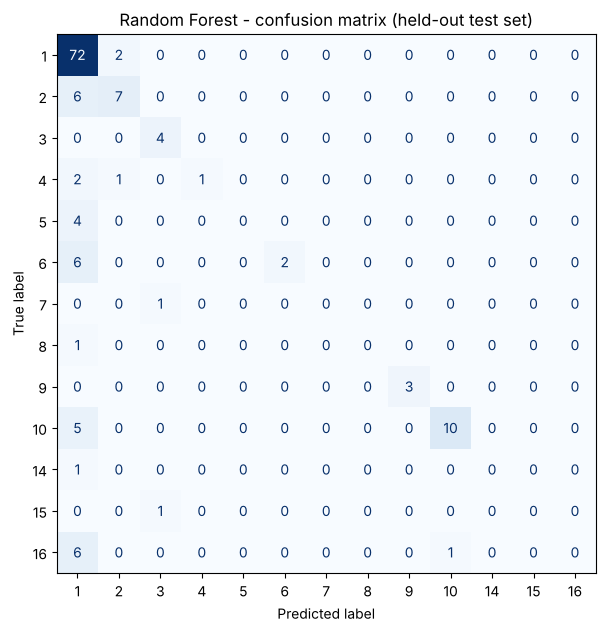

              precision    recall  f1-score   support

           1       0.70      0.97      0.81        74
           2       0.70      0.54      0.61        13
           3       0.67      1.00      0.80         4
           4       1.00      0.25      0.40         4
           5       0.00      0.00      0.00         4
           6       1.00      0.25      0.40         8
           7       0.00      0.00      0.00         1
           8       0.00      0.00      0.00         1
           9       1.00      1.00      1.00         3
          10       0.91      0.67      0.77        15
          14       0.00      0.00      0.00         1
          15       0.00      0.00      0.00         1
          16       0.00      0.00      0.00         7

    accuracy                           0.73       136
   macro avg       0.46      0.36      0.37       136
weighted avg       0.68      0.73      0.67       136



In [10]:
pred_rf = rf.predict(X_te)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y_te, pred_rf, ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Random Forest - confusion matrix (held-out test set)"); plt.show()
print(classification_report(y_te, pred_rf, zero_division=0))

## 10. Feature importance (Random Forest)
How much each feature contributed to the forest's splits. This describes the **model**, it does not prove a cause.

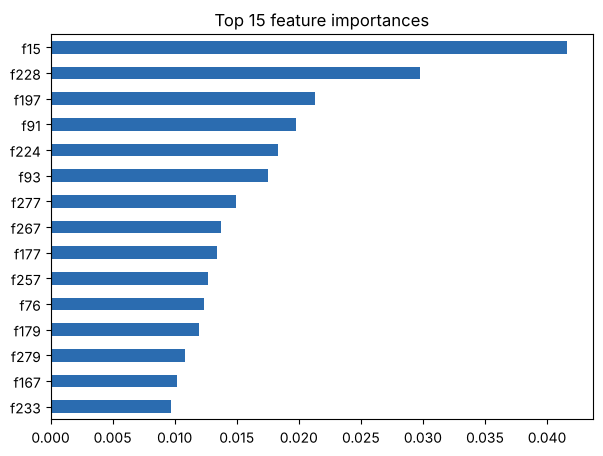

In [11]:
kept = rf.named_steps["drop"].keep_
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=kept).nlargest(15)[::-1]
imp.plot.barh(figsize=(7, 5), color="#2b6cb0"); plt.title("Top 15 feature importances"); plt.show()

## 11. The CART tree (top 3 levels shown for readability)

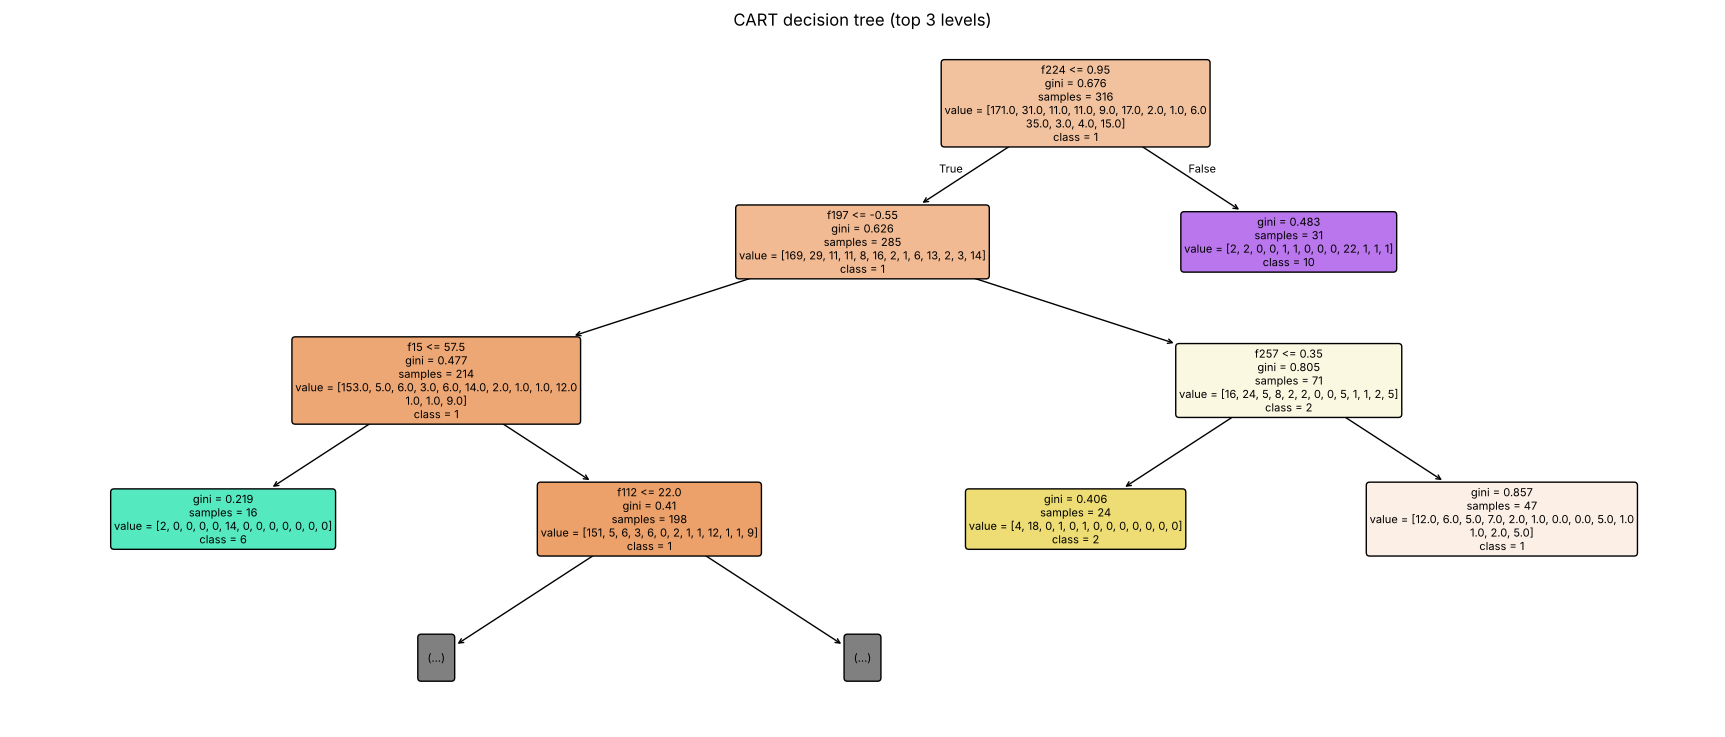

In [12]:
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(cart.named_steps["model"], max_depth=3, feature_names=list(cart.named_steps["drop"].keep_),
          class_names=[str(c) for c in cart.classes_], filled=True, rounded=True, fontsize=8, ax=ax)
plt.title("CART decision tree (top 3 levels)"); plt.show()

## 12. Comparison with the reference paper
| | Paper (Stanford) | This notebook |
|---|---|---|
| Language / library | R, `rpart` | Python, scikit-learn |
| Missing values | dropped feature 14; imputed the rest with rpart | drop >50 %-missing features (train only); median imputation |
| Pruning | rpart complexity parameter | `ccp_alpha`, chosen by cross-validation on training rows |
| Validation | 50/50, 70/30, 100/100 splits, 10-fold CV | one 70/30 split + 10-fold CV (3 repeats) |
| Reported accuracy | ~80 % (their protocol) | **see the table in section 8 — our own numbers** |

The paper's ~80 % is historical context, **not our result**, and this is not an exact reproduction of its protocol.

## 13. Limitations
Only 452 patients; several classes have 1–5 patients, so per-class results are noisy and rare classes are mostly missed; one split; simple imputation; feature importance is not causal; precomputed features (no raw ECG); historical single-source data; no external validation.

## 14. Conclusion
Random Forest beats the single pruned CART tree on this data, while CART gives readable rules. Both are well below perfect, mainly because of the tiny rare classes. Choices were made with training data only; the test set was used once.

> **{D}**